| Graph | Variables | What it tells you | Priority |
|---|---|---|---|
| **Population growth choropleth** | Population 2026 → 2036 | Where population growth/decline is forecast | ✅ Already done |
| **Dwelling growth choropleth** | Dwellings 2026 → 2036 | Where housing stock is forecast to expand | ⭐⭐⭐ |
| **Population vs dwelling growth scatter** | Population growth % vs dwelling growth % | Whether dwelling growth is keeping pace with population | ⭐⭐⭐ |
| **Population–dwelling growth gap map** | Population growth % − dwelling growth % | Spatial areas where population growth exceeds dwelling growth | ⭐⭐⭐ |
| **Top/bottom SA2 growth bar chart** | Population growth % | Fastest growing and declining SA2s | ⭐⭐ |
| **Population pyramid** | Male/Female × age | Demographic structure in 2026 vs 2036 | ⭐⭐⭐ |
| **Age-group growth chart** | Persons by age | Which age groups are driving growth | ⭐⭐⭐ |
| **Population per dwelling map** | Population ÷ dwellings | Potential changes in housing occupancy/pressure | ⭐⭐⭐ |
| **Victoria population trajectory** | 2021/26/31/36 | Overall population forecast | ⭐ |
| **Victoria dwelling trajectory** | 2021/26/31/36 | Overall dwelling-stock forecast | ⭐ |
| **Population change by Region_Type** | Region_Type + population | Compare geographic categories in your source data | ⭐⭐ |

In [1]:
# Again Lets start with some imports...

from pathlib import Path

import geopandas as gpd
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.colors import Normalize
from matplotlib.patches import Patch

In [2]:
# Now to write paths to read in my data :)

Current_Path = Path.cwd()

Path_Root = Current_Path.parent.parent
Data_Path = Path_Root / "data" / "forecasting"
Forecast_Pop_File_Path = Data_Path / "SAP_Forecast_2136_Cleaned.csv"

Area_Path = Path_Root / "data" / "area_zones_data"
Area_File_Path = Area_Path / "Vic_Area_Zones.shp"

Forecast_Dwl_File_Path = Data_Path / "Household_Dwelling_Forecast_2136_CleanedV2.csv"

In [3]:
# Read in my data

Pop_Data = pd.read_csv(Forecast_Pop_File_Path)

Dwl_Data = pd.read_csv(Forecast_Dwl_File_Path)

Vic_Area_Zones = gpd.read_file(Area_File_Path)

In [4]:
# Now to get pop & dwelling growth percentages

# Now define the age groups

Age_Groups = [
    "0-4",
    "5-9",
    "10-14",
    "15-19",
    "20-24",
    "25-29",
    "30-34",
    "35-39",
    "40-44",
    "45-49",
    "50-54",
    "55-59",
    "60-64",
    "65-69",
    "70-74",
    "75-79",
    "80-84",
    "85+"
]

# Now to calc the total pop for each SA2 

Pop_Data["Population_2026"] = Pop_Data[
    [f"Persons_2026_{age}" for age in Age_Groups]
].sum(axis=1)

Pop_Data["Population_2036"] = Pop_Data[
    [f"Persons_2036_{age}" for age in Age_Groups]
].sum(axis=1)

# Now to calc pop growth for each SA2

Pop_Data["Population_Growth_Percent"] = (
    (
        Pop_Data["Population_2036"]
        - Pop_Data["Population_2026"]
    )
    / Pop_Data["Population_2026"]
) * 100

# Now to calc the dwelling growth percent from 2026 to 2036

Dwl_Data["Dwelling_Growth_Percent"] = (
    (
        Dwl_Data["Dwellings_2036"]
        - Dwl_Data["Dwellings_2026"]
    )
    / Dwl_Data["Dwellings_2026"]
) * 100

In [5]:
# Now to deal with inf and NaN values in the pop growth percent column

# Now to deal with a 2026 population of 0,

Pop_Data.loc[
    Pop_Data["Population_2026"] == 0,
    "Population_Growth_Percent"
] = np.nan

# Now to deal with NaN values

Dwl_Data.loc[
    Dwl_Data["Dwellings_2026"] == 0,
    "Dwelling_Growth_Percent"
] = np.nan

In [6]:
# Making sure types are the same

Pop_Data["SA2_Code"] = (
    Pop_Data["SA2_Code"]
    .astype(str)
    .str.strip()
)

Dwl_Data["SA2_Code"] = (
    Dwl_Data["SA2_Code"]
    .astype(str)
    .str.strip()
)

Vic_Area_Zones["SA2_CODE21"] = (
    Vic_Area_Zones["SA2_CODE21"]
    .astype(str)
    .str.strip()
)


In [7]:
# Now to merge the subsets together!!!

Pop_Map = Vic_Area_Zones.merge(
    Pop_Data[
        [
            "SA2_Code",
            "Population_2026",
            "Population_2036",
            "Population_Growth_Percent"
        ]
    ],
    left_on="SA2_CODE21",
    right_on="SA2_Code",
    how="left"
)

Growth_Comparison = Pop_Map[
    [
        "SA2_CODE21",
        "SA2_NAME21",
        "Population_Growth_Percent"
    ]
].merge(
    Dwl_Data[
        [
            "SA2_Code",
            "Dwelling_Growth_Percent"
        ]
    ],
    left_on="SA2_CODE21",
    right_on="SA2_Code",
    how="left"
)

In [8]:
# Now to remove any invalid values from the growth comparison dataframe

Growth_Comparison = Growth_Comparison.replace(
    [np.inf, -np.inf],
    np.nan
)

Growth_Comparison = Growth_Comparison.dropna(
    subset=[
        "Population_Growth_Percent",
        "Dwelling_Growth_Percent"
    ]
)

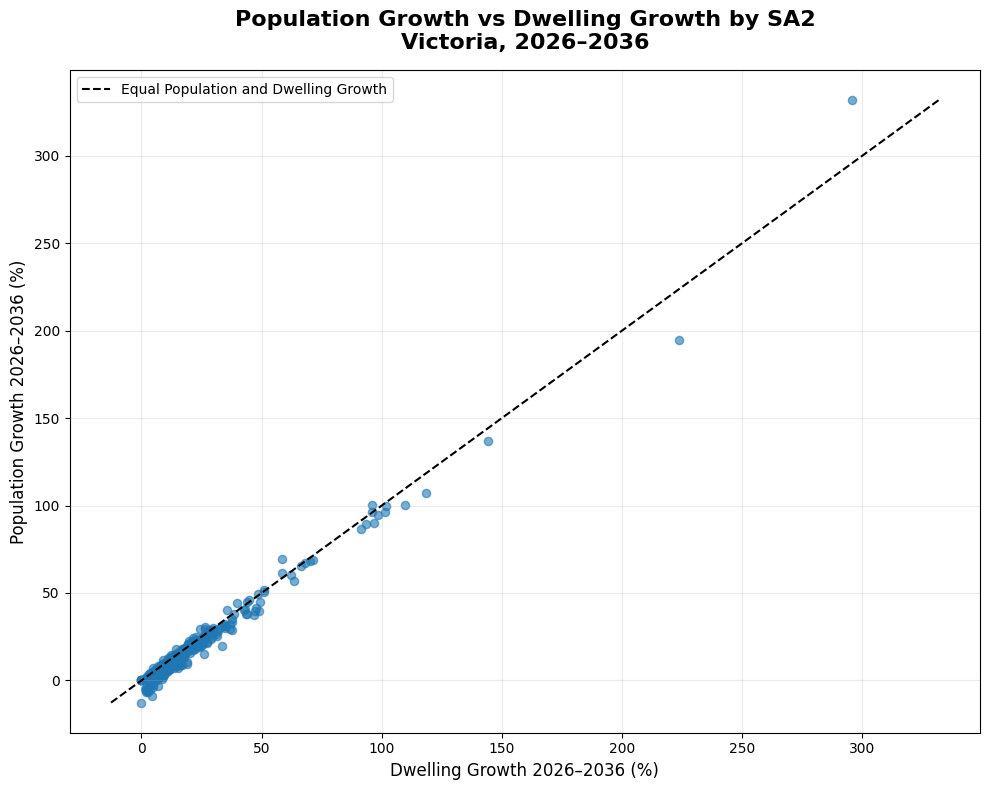

In [9]:
# Now to plot!!

# Population vs dwelling growth scatterplot

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    Growth_Comparison["Dwelling_Growth_Percent"],
    Growth_Comparison["Population_Growth_Percent"],
    alpha=0.6,
    s=35
)

# Add equality line: Population Growth = Dwelling Growth

max_value = max(
    Growth_Comparison["Dwelling_Growth_Percent"].max(),
    Growth_Comparison["Population_Growth_Percent"].max()
)

min_value = min(
    Growth_Comparison["Dwelling_Growth_Percent"].min(),
    Growth_Comparison["Population_Growth_Percent"].min()
)

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Equal Population and Dwelling Growth"
)
# Formatting

ax.set_xlabel(
    "Dwelling Growth 2026–2036 (%)",
    fontsize=12
)

ax.set_ylabel(
    "Population Growth 2026–2036 (%)",
    fontsize=12
)

ax.set_title(
    "Population Growth vs Dwelling Growth by SA2\n"
    "Victoria, 2026–2036",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.legend()

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

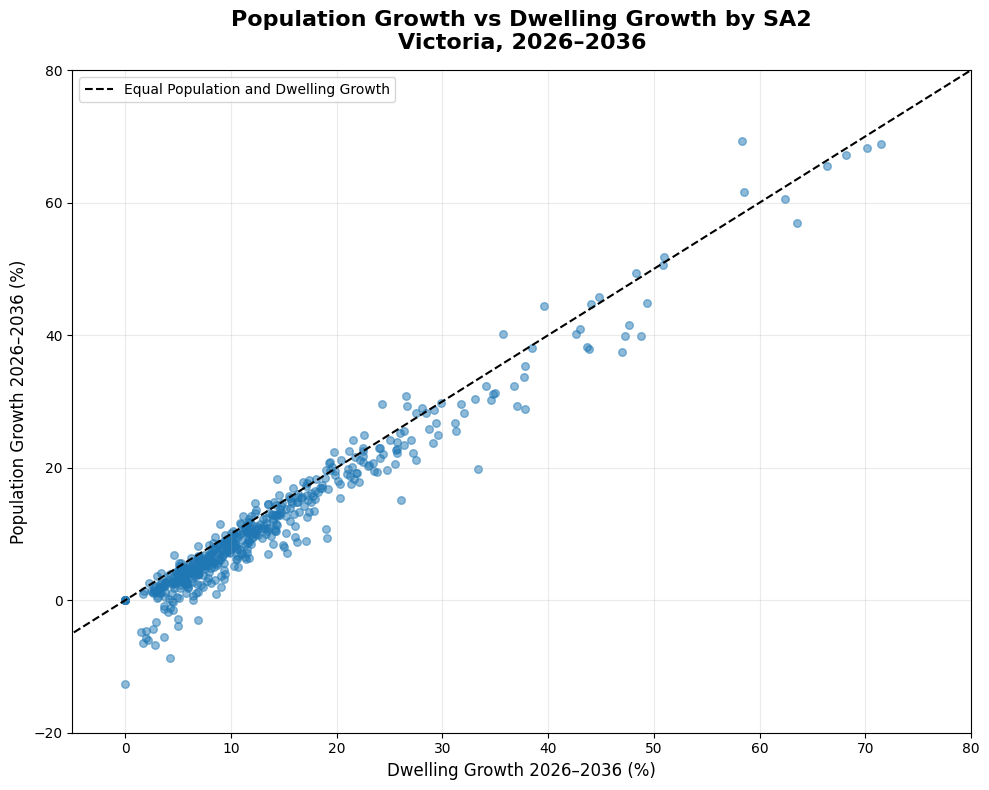

In [10]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    Growth_Comparison["Dwelling_Growth_Percent"],
    Growth_Comparison["Population_Growth_Percent"],
    alpha=0.5,
    s=30
)


# --------------------------------------------------
# Equality line
# --------------------------------------------------

ax.plot(
    [-20, 80],
    [-20, 80],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Equal Population and Dwelling Growth"
)


# --------------------------------------------------
# Zoom into majority of observations
# --------------------------------------------------

ax.set_xlim(-5, 80)
ax.set_ylim(-20, 80)


# --------------------------------------------------
# Labels
# --------------------------------------------------

ax.set_xlabel(
    "Dwelling Growth 2026–2036 (%)",
    fontsize=12
)

ax.set_ylabel(
    "Population Growth 2026–2036 (%)",
    fontsize=12
)

ax.set_title(
    "Population Growth vs Dwelling Growth by SA2\n"
    "Victoria, 2026–2036",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.legend(
    loc="upper left",
    fontsize=10
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

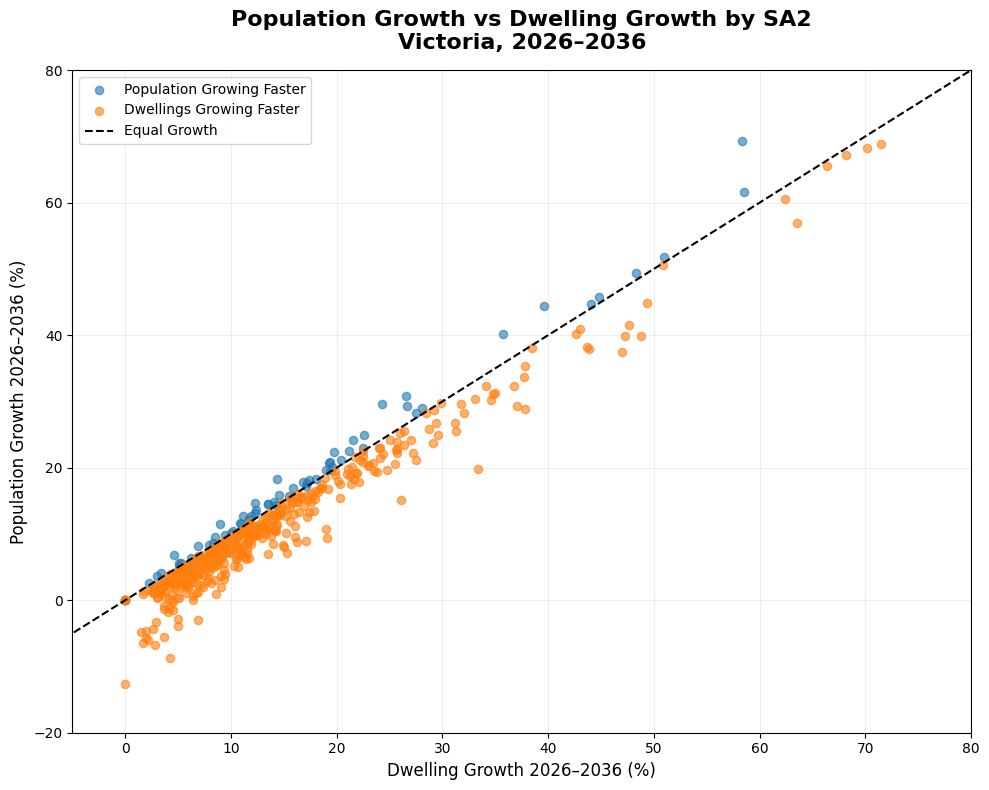

In [11]:
Above_Line = (
    Growth_Comparison["Population_Growth_Percent"]
    >
    Growth_Comparison["Dwelling_Growth_Percent"]
)

fig, ax = plt.subplots(figsize=(10, 8))

# Population growing faster
ax.scatter(
    Growth_Comparison.loc[
        Above_Line,
        "Dwelling_Growth_Percent"
    ],
    Growth_Comparison.loc[
        Above_Line,
        "Population_Growth_Percent"
    ],
    alpha=0.6,
    s=35,
    label="Population Growing Faster"
)

# Dwellings growing faster
ax.scatter(
    Growth_Comparison.loc[
        ~Above_Line,
        "Dwelling_Growth_Percent"
    ],
    Growth_Comparison.loc[
        ~Above_Line,
        "Population_Growth_Percent"
    ],
    alpha=0.6,
    s=35,
    label="Dwellings Growing Faster"
)

# Equality line
ax.plot(
    [-20, 80],
    [-20, 80],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Equal Growth"
)

ax.set_xlim(-5, 80)
ax.set_ylim(-20, 80)

ax.set_xlabel(
    "Dwelling Growth 2026–2036 (%)",
    fontsize=12
)

ax.set_ylabel(
    "Population Growth 2026–2036 (%)",
    fontsize=12
)

ax.set_title(
    "Population Growth vs Dwelling Growth by SA2\n"
    "Victoria, 2026–2036",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.legend(fontsize=10)

ax.grid(
    alpha=0.2
)

plt.tight_layout()
plt.show()

In [12]:
# --------------------------------------------------
# Create growth comparison category
# --------------------------------------------------

Growth_Comparison["Growth_Category"] = np.where(
    Growth_Comparison["Population_Growth_Percent"]
    > Growth_Comparison["Dwelling_Growth_Percent"],
    "Population Growth Exceeds Dwelling Growth",
    "Dwelling Growth Exceeds Population Growth"
)


# --------------------------------------------------
# Join growth comparison to Victorian SA2 boundaries
# --------------------------------------------------

Growth_Map = Vic_Area_Zones.merge(
    Growth_Comparison[
        [
            "SA2_CODE21",
            "Growth_Category"
        ]
    ],
    on="SA2_CODE21",
    how="left"
)

In [13]:
# now for a growth difference + or - 0.5% are considered approx equal growth

Growth_Comparison["Growth_Difference"] = (
    Growth_Comparison["Population_Growth_Percent"]
    - Growth_Comparison["Dwelling_Growth_Percent"]
)

Growth_Comparison["Growth_Category"] = np.select(
    [
        Growth_Comparison["Growth_Difference"] > 0.5,
        Growth_Comparison["Growth_Difference"] < -0.5
    ],
    [
        "Population Growth Exceeds Dwelling Growth",
        "Dwelling Growth Exceeds Population Growth"
    ],
    default="Approximately Equal Growth"
)

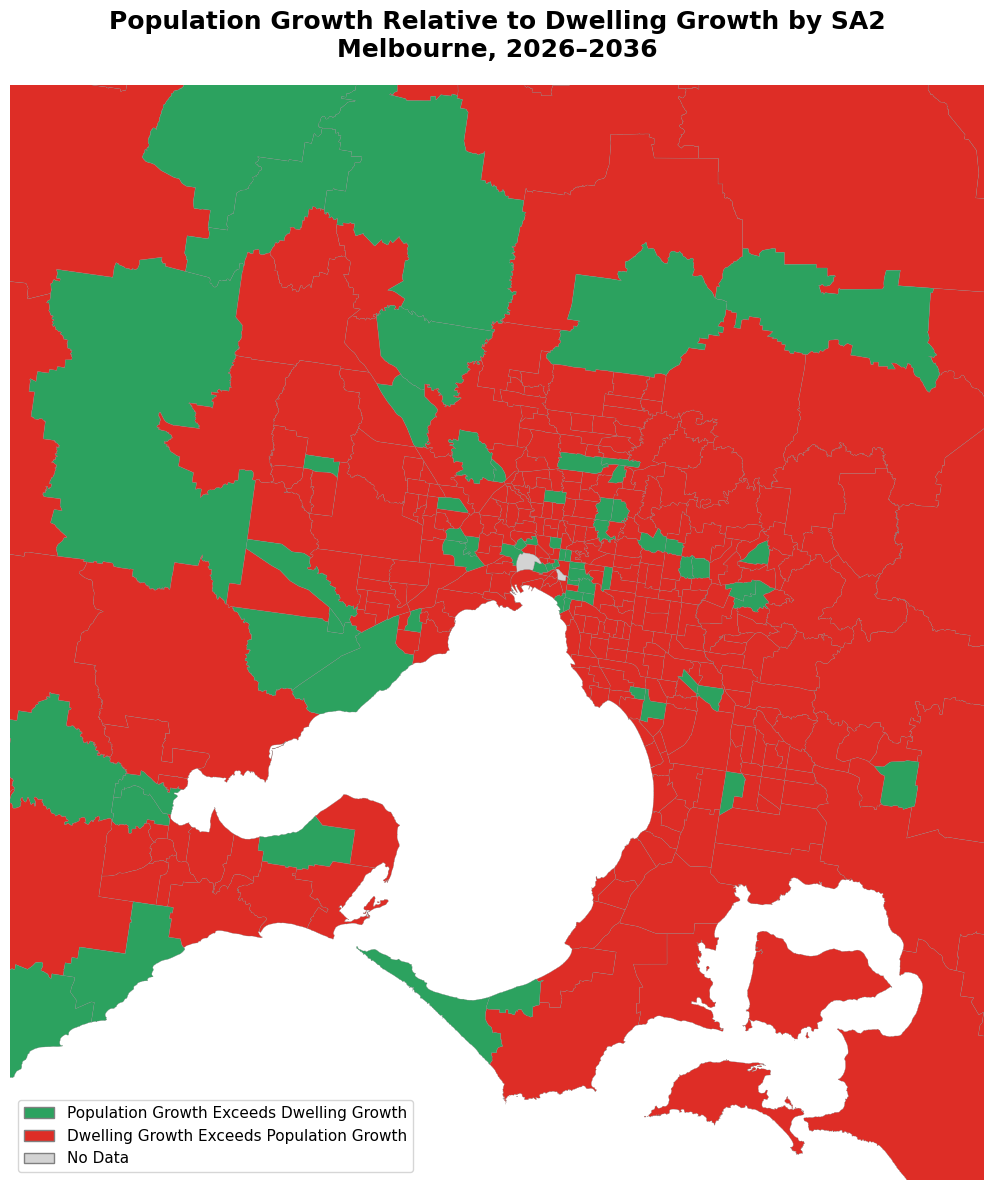

In [14]:
# --------------------------------------------------
# Set colours
# --------------------------------------------------

Growth_Colours = {
    "Population Growth Exceeds Dwelling Growth": "#2ca25f",
    "Dwelling Growth Exceeds Population Growth": "#de2d26"
}

Growth_Map["Plot_Colour"] = (
    Growth_Map["Growth_Category"]
    .map(Growth_Colours)
    .fillna("lightgrey")
)


# --------------------------------------------------
# Create figure
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 12)
)


# --------------------------------------------------
# Plot SA2s
# --------------------------------------------------

Growth_Map.plot(
    color=Growth_Map["Plot_Colour"],
    linewidth=0.2,
    edgecolor="grey",
    ax=ax
)


# --------------------------------------------------
# Create legend
# --------------------------------------------------

legend_elements = [
    Patch(
        facecolor="#2ca25f",
        edgecolor="grey",
        label="Population Growth Exceeds Dwelling Growth"
    ),
    Patch(
        facecolor="#de2d26",
        edgecolor="grey",
        label="Dwelling Growth Exceeds Population Growth"
    ),
    Patch(
        facecolor="lightgrey",
        edgecolor="grey",
        label="No Data"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    fontsize=11,
    frameon=True
)

# Zoom into Inner Melbourne
ax.set_xlim(144.10, 145.65)
ax.set_ylim(-38.60, -37.20)


# --------------------------------------------------
# Formatting
# --------------------------------------------------

ax.set_title(
    "Population Growth Relative to Dwelling Growth by SA2\n"
    "Melbourne, 2026–2036",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()

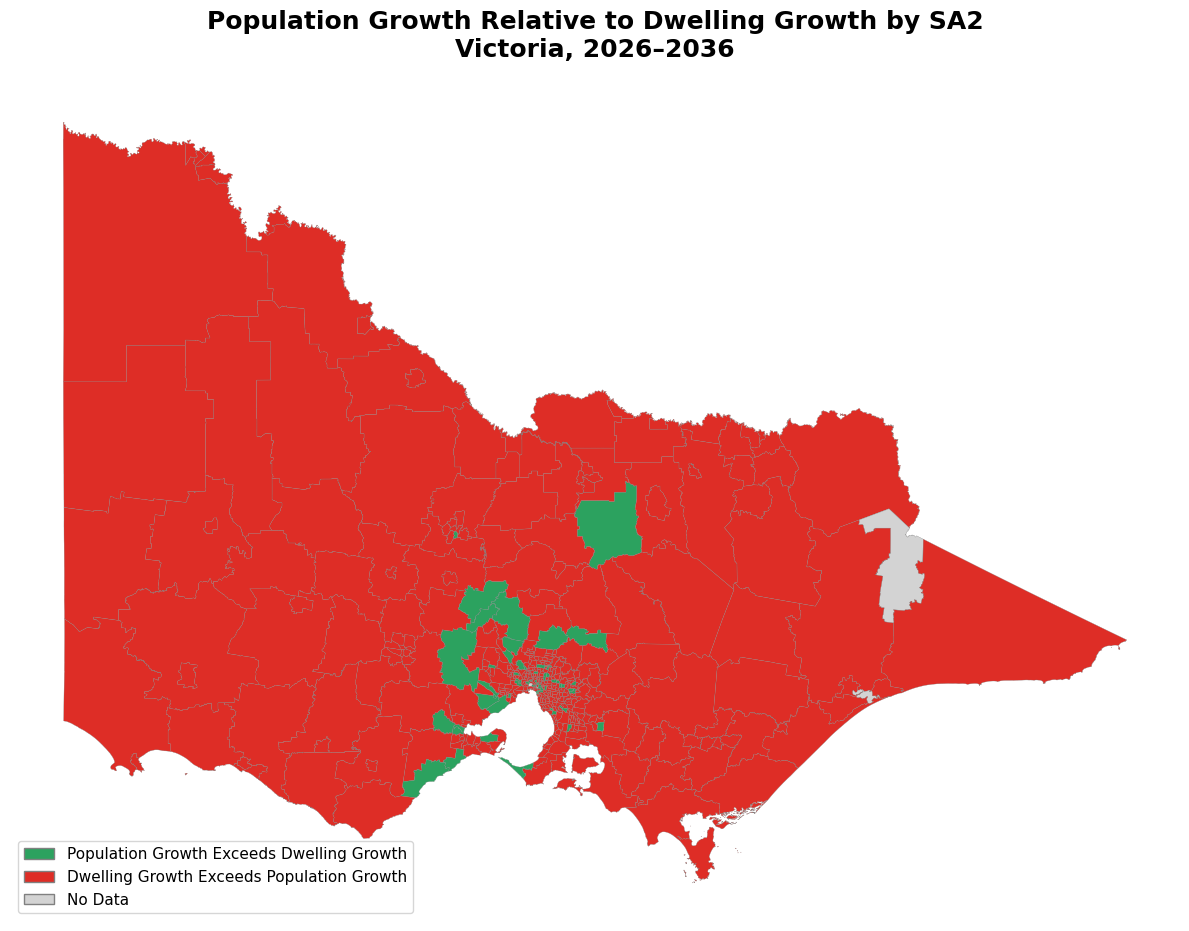

In [15]:
# --------------------------------------------------
# Set colours
# --------------------------------------------------

Growth_Colours = {
    "Population Growth Exceeds Dwelling Growth": "#2ca25f",
    "Dwelling Growth Exceeds Population Growth": "#de2d26"
}

Growth_Map["Plot_Colour"] = (
    Growth_Map["Growth_Category"]
    .map(Growth_Colours)
    .fillna("lightgrey")
)


# --------------------------------------------------
# Create figure
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 12)
)


# --------------------------------------------------
# Plot SA2s
# --------------------------------------------------

Growth_Map.plot(
    color=Growth_Map["Plot_Colour"],
    linewidth=0.2,
    edgecolor="grey",
    ax=ax
)


# --------------------------------------------------
# Create legend
# --------------------------------------------------

legend_elements = [
    Patch(
        facecolor="#2ca25f",
        edgecolor="grey",
        label="Population Growth Exceeds Dwelling Growth"
    ),
    Patch(
        facecolor="#de2d26",
        edgecolor="grey",
        label="Dwelling Growth Exceeds Population Growth"
    ),
    Patch(
        facecolor="lightgrey",
        edgecolor="grey",
        label="No Data"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    fontsize=11,
    frameon=True
)


# --------------------------------------------------
# Formatting
# --------------------------------------------------

ax.set_title(
    "Population Growth Relative to Dwelling Growth by SA2\n"
    "Victoria, 2026–2036",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:

Growth_Comparison_Sorted = (
    Growth_Comparison
    .sort_values(
        "Growth_Difference",
        ascending=False
    )
)

Growth_Comparison_Sorted[
    [
        "SA2_CODE21",
        "SA2_NAME21",
        "Population_Growth_Percent",
        "Dwelling_Growth_Percent",
        "Growth_Difference"
    ]
].head(20)

,SA2_CODE21,SA2_NAME21,Population_Growth_Percent,Dwelling_Growth_Percent,Growth_Difference
130,206041120,Flemington Racecourse,331.844821,295.857988,35.986833
344,212011551,Pakenham - South East,69.316592,58.297347,11.019244
40,203021040,Geelong West - Hamlyn Heights,29.598411,24.278105,5.320306
281,210041540,Sunbury - South,44.333732,39.577836,4.755896
401,213011336,Sunshine,40.146330,35.737492,4.408838
46,203021047,North Geelong - Bell Park,30.746006,26.549333,4.196673
247,209041225,Whittlesea,100.291872,96.121818,4.170054
394,213011328,Ardeer - Albion,18.249166,14.364064,3.885102
442,213051468,Werribee - West,61.545670,58.488144,3.057526
380,212041563,Dandenong - North,29.368338,26.629696,2.738642
